In [1]:
!pip install -q albumentations opencv-python matplotlib

In [2]:
import torch
import torchvision
import cv2
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Albumentations:", A.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
OpenCV: 4.14.0
Albumentations: 2.0.8
CUDA Available: True
GPU: Tesla T4


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

base_path = "/content/drive/MyDrive"

print("Folders in Google Drive:\n")

for item in os.listdir(base_path):
    print(item)

Folders in Google Drive:

Colab Notebooks
Google Meet
Aksha-Version-2.1-main_Keshav.zip
Aksha-Version-2.1-main.zip
mobile detection dataset
Intern Training Program


In [8]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, '').count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

MyDrive/
  Aksha-Version-2.1-main_Keshav.zip
  Aksha-Version-2.1-main.zip
  Colab Notebooks/
    Day-3 Training Program.ipynb
    Untitled0.ipynb
    Untitled1.ipynb
    Day-1 Training Program.ipynb
    Day-2 Training Program.ipynb
  Google Meet/
    Aksha Daily standup (recurring)/
      Aksha Daily standup - 2026 09 21 11:00 IST - Notes by Gemini.gdoc
      Aksha Daily standup - 2026 09 28 10:57 IST - Notes by Gemini.gdoc
      Aksha Daily standup - 2026 10 15 10:59 IST - Notes by Gemini.gdoc
      Aksha Daily standup - 2026 10 19 11:00 IST - Notes by Gemini.gdoc
      Aksha Daily standup - 2026 10 20 11:02 IST - Notes by Gemini.gdoc
    Aksha - Weekly  Demo - With Aniruddha sir (recurring)/
      Aksha - Weekly  Demo - With Aniruddha sir - 2026 11 03 15:29 IST - Notes by Gemini.gdoc
      Aksha - Weekly  Demo - With Aniruddha sir - 2026 11 10 15:30 IST - Notes by Gemini.gdoc
      Aksha - Weekly  Demo - With Aniruddha sir - 2026 11 24 15:44 IST - Notes by Gemini.gdoc
    Aksha & CV 

In [9]:
import os

base_path = "/content/drive/MyDrive/Intern Training Program/Day-3"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")
    print(f"{indent}  Files: {len(files)}")

    for file in files[:5]:
        print(f"{indent}  - {file}")

Day-3/
  Files: 0
  images/
    Files: 700
    - sorted_2026-06-25 00_02_22.jpg
    - sorted_2026-06-25 00_02_27.jpg
    - sorted_2026-06-25 00_01_26.jpg
    - sorted_2026-06-25 00_00_17.jpg
    - sorted_2026-06-25 00_00_28.jpg


Total images: 700
Sample image shape: (360, 640, 3)


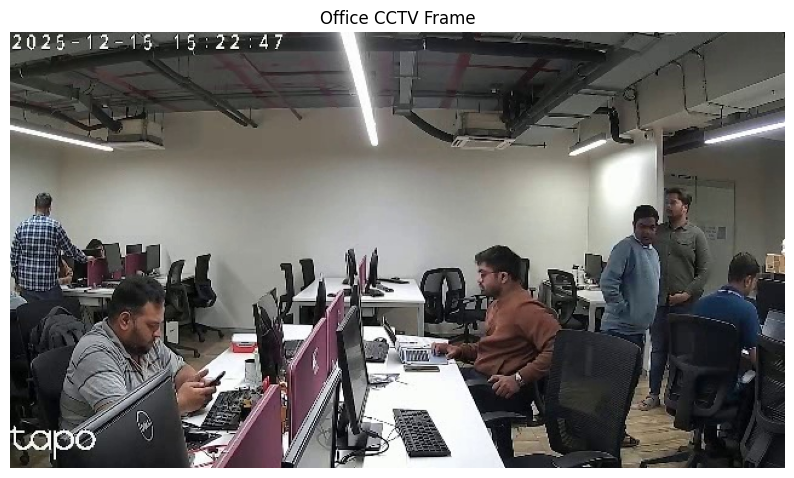

In [10]:
import os
import cv2
import matplotlib.pyplot as plt

image_dir = "/content/drive/MyDrive/Intern Training Program/Day-3/images"

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images:", len(image_files))

sample_path = os.path.join(image_dir, image_files[0])
sample = cv2.imread(sample_path)

print("Sample image shape:", sample.shape)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB))
plt.title("Office CCTV Frame")
plt.axis("off")
plt.show()

In [11]:
import os
import cv2
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader, Subset
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Dataset path
image_dir = "/content/drive/MyDrive/Intern Training Program/Day-3/images"

# Training transformations
train_transform = A.Compose([
    A.Resize(height=224, width=224),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

# Validation transformations
val_transform = A.Compose([
    A.Resize(height=224, width=224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


class CCTVImageDataset(Dataset):

    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform

        self.image_files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        image_name = self.image_files[index]
        image_path = os.path.join(self.image_dir, image_name)

        image = cv2.imread(image_path)

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, image_name


# Create dataset
dataset = CCTVImageDataset(image_dir)

print("Total dataset images:", len(dataset))
print("Dataset class:", type(dataset).__name__)

Total dataset images: 700
Dataset class: CCTVImageDataset


In [12]:
from torch.utils.data import DataLoader, Subset
import torch

# Reproducible split
torch.manual_seed(42)

total_images = len(dataset)
train_size = int(0.8 * total_images)
val_size = total_images - train_size

indices = torch.randperm(total_images).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:]

# Separate datasets so each gets its own transformations
train_full = CCTVImageDataset(
    image_dir,
    transform=train_transform
)

val_full = CCTVImageDataset(
    image_dir,
    transform=val_transform
)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(val_full, val_indices)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training images: 560
Validation images: 140
Training batches: 35
Validation batches: 9


Batch shape: torch.Size([16, 3, 224, 224])
Number of images: 16
Image tensor type: torch.float32


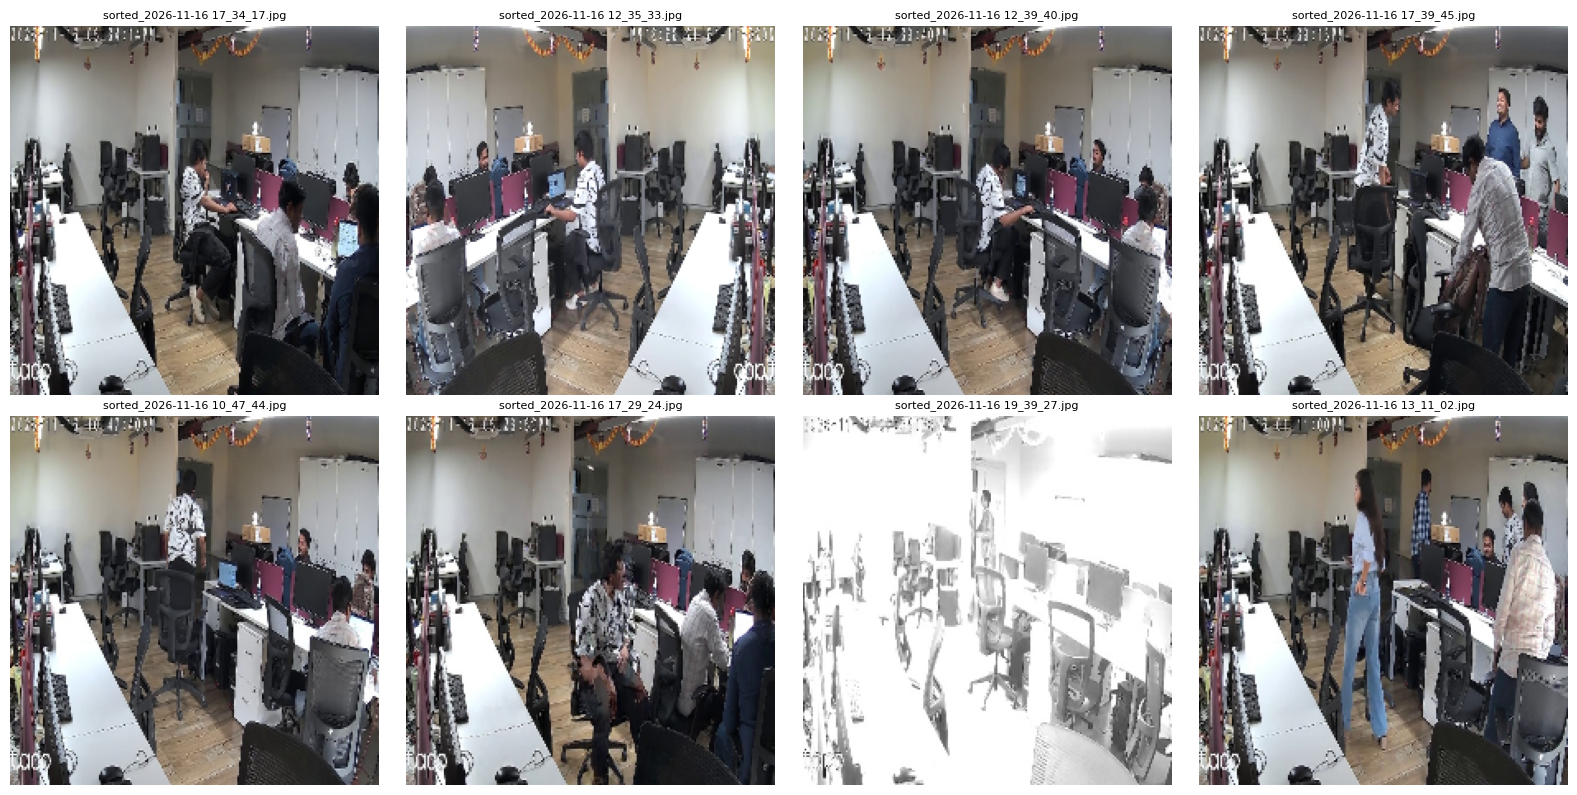

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch
images, image_names = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Number of images:", len(images))
print("Image tensor type:", images.dtype)

# Reverse normalization for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    image = images[i].cpu() * std + mean
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(image_names[i], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
%%writefile dataset.py

import os
import cv2
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import albumentations as A
from albumentations.pytorch import ToTensorV2


def get_transforms(training=True):
    if training:
        return A.Compose([
            A.Resize(224, 224),
            A.HorizontalFlip(p=0.5),
            A.RandomBrightnessContrast(p=0.3),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)
            ),
            ToTensorV2()
        ])

    return A.Compose([
        A.Resize(224, 224),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),
        ToTensorV2()
    ])


class CCTVImageDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform

        self.image_files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        image_name = self.image_files[index]
        image_path = os.path.join(self.image_dir, image_name)

        image = cv2.imread(image_path)

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, image_name


def create_dataloaders(
    image_dir,
    batch_size=16,
    train_ratio=0.8,
    seed=42
):
    train_full = CCTVImageDataset(
        image_dir, get_transforms(training=True)
    )

    val_full = CCTVImageDataset(
        image_dir, get_transforms(training=False)
    )

    total = len(train_full)
    train_size = int(total * train_ratio)
    val_size = total - train_size

    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(total, generator=generator).tolist()

    train_dataset = Subset(train_full, indices[:train_size])
    val_dataset = Subset(val_full, indices[train_size:])

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader

Writing dataset.py


In [16]:
import shutil
import os

source = "/content/dataset.py"
destination = "/content/drive/MyDrive/Intern Training Program/Day-3/dataset.py"

shutil.move(source, destination)

print("File exists:", os.path.exists(destination))
print("Saved at:", destination)

File exists: True
Saved at: /content/drive/MyDrive/Intern Training Program/Day-3/dataset.py


In [17]:
import sys
import os

project_dir = "/content/drive/MyDrive/Intern Training Program/Day-3"

print("dataset.py exists:", os.path.exists(
    os.path.join(project_dir, "dataset.py")
))

if project_dir not in sys.path:
    sys.path.append(project_dir)

from dataset import CCTVImageDataset, create_dataloaders

print("Import successful!")

dataset.py exists: True
Import successful!


In [18]:
image_dir = os.path.join(project_dir, "images")

train_loader, val_loader = create_dataloaders(
    image_dir,
    batch_size=16
)

images, names = next(iter(train_loader))

print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test batch shape:", images.shape)

Training images: 560
Validation images: 140
Test batch shape: torch.Size([16, 3, 224, 224])


In [19]:
%%writefile requirements.txt
torch
torchvision
opencv-python
albumentations
numpy
matplotlib

Writing requirements.txt


In [20]:
import shutil
import os

source = "/content/requirements.txt"
destination = "/content/drive/MyDrive/Intern Training Program/Day-3/requirements.txt"

shutil.move(source, destination)

print("Requirements file saved:", os.path.exists(destination))

Requirements file saved: True


In [21]:
%%writefile README.md
# Day 3 - PyTorch Data Pipeline

## Objective
Build a reusable PyTorch Dataset and DataLoader pipeline using real office CCTV image frames.

## Dataset
- Total images: 700
- Training images: 560 (80%)
- Validation images: 140 (20%)
- Image format: JPG
- Original image dimensions: 360 x 640

## Implementation
- Custom PyTorch Dataset
- PyTorch DataLoader
- Albumentations image augmentation
- Image resizing to 224 x 224
- Image normalization
- Training and validation split
- Batch visualization

## Files
- images/: CCTV image frames
- dataset.py: Reusable Dataset and DataLoader implementation
- requirements.txt: Required Python packages

## Verification
- Dataset import successful
- Training and validation DataLoaders created successfully
- Test batch shape: [16, 3, 224, 224]

## Note
This exercise uses unlabelled CCTV images for data pipeline practice.
It does not train an object detection model.

Writing README.md


In [22]:
source = "/content/README.md"
destination = "/content/drive/MyDrive/Intern Training Program/Day-3/README.md"

shutil.move(source, destination)

print("README saved:", os.path.exists(destination))

README saved: True


In [23]:
import os

base = "/content/drive/MyDrive/Intern Training Program/Day-3"

for filename in ["dataset.py", "requirements.txt", "README.md"]:
    path = os.path.join(base, filename)
    print(filename, ":", "FOUND" if os.path.exists(path) else "MISSING")

print("Images:", len(os.listdir(os.path.join(base, "images"))))

dataset.py : FOUND
requirements.txt : FOUND
README.md : FOUND
Images: 700
